# yolov8n-coco on voc — inference

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lrivals/EmbeddedComputervision/blob/main/notebooks/voc/yolov8n-coco_infer.ipynb)

Role: inference; tier **R** on the first pass (`SUBSET = 50`), **N** on the full split (4952 images, `SUBSET = 0`). **Full run by default** (`SUBSET = 0`); set `SUBSET = 50` for a quick try. Tasks: [T11.2](../../docs/tasks/M11-jeux-de-donnees.md), [T35.6](../../docs/tasks/M35-yolov8n.md);
notebooks: [M14](../../docs/tasks/M14-notebooks.md). Out-of-domain COCO weights: only the shared classes are evaluated.

Prerequisites:
- data: `data/VOCdevkit/VOC2007/ImageSets/Main/test.txt` — tools/get_voc.sh
- weights: `weights/ultralytics/yolov8n.pt` — Ultralytics checkpoint, AGPL-3.0, local only (neither on Drive nor fetched by tools/get_weights.sh): copy it to weights/ultralytics/ (Colab: upload it)

Each step prints the `python tools/…` command it runs: a result can be reproduced
from the command line. Outputs in `build/notebooks/voc/yolov8n-coco/`, never in `results/` (an mAP on `SUBSET`
images is not publishable, M12 rules). Notebook generated by
`python -m tools.notebooks` (`make notebooks`): edit the template
`tools/notebooks/gabarits.py`, not this file.

## Parameters

In [1]:
NET       = 'yolov8n-coco'  # name in CFG_FILES or cfg (relative to the root)
DATASET   = 'voc'  # key of DATASETS
SPLIT     = None  # None: evaluation split of the dataset
WEIGHTS   = 'weights/ultralytics/yolov8n.pt'  # weights evaluated
DEVICE    = 'cpu'  # cpu | gpu (training only; the rest on CPU)
SUBSET    = 0  # images evaluated; 0: full split (tier N)
SIZE      = None  # input WxH (e.g. '640x192'); None: the one of the cfg
RESIZE    = 'v5'  # v5 (letterbox and thresholds of YOLOv5, T33.4)
PRESET    = 'v8'  # eval_voc preset with RESIZE v5: NMS 0.7 of YOLOv8 (T35.3)
METRIC    = None  # None: the one of the dataset (coco for coco and flir)
DATA_ROOT = None  # dataset root; None: data/<dataset> (Colab: Drive folder)
DRIVE_DIR = '/content/drive/MyDrive/EmbeddedCV'  # Colab: archives data/<dataset>.tar; None: no Drive
JOBS      = None  # evaluation processes; None: one per CPU core, capped by the memory (Colab TPU runtime: dozens)
SHOW      = 6  # images shown
OUT       = 'build/notebooks/voc/yolov8n-coco'  # notebook outputs
REPO_URL  = 'https://github.com/lrivals/EmbeddedComputervision.git'  # Colab: cloned repository
REV       = 'main'  # Colab: revision

## Environment

Local: nothing is installed or downloaded, the cell checks the prerequisites and
stops with the command to run. Colab: clone of the repository, installation, CuPy if
`DEVICE = "gpu"`, weights, then data by `colab.prepare_data` (archive
`<DRIVE_DIR>/data/<dataset>.tar` or direct download; ExDark and FLIR: archive only,
made on the PC by `tools/get_datasets.sh pack <dataset>`).

In [2]:
import os
import subprocess
import sys
from pathlib import Path

COLAB = "google.colab" in sys.modules


def repo_root():
    for d in (Path.cwd(), *Path.cwd().parents):
        if (d / "tools" / "notebooks" / "commandes.py").exists():
            return d
    return None


ROOT = repo_root()
if COLAB:
    if ROOT is None:
        ROOT = Path("/content/EmbeddedComputervision")
        if not ROOT.exists():
            subprocess.run(["git", "clone", REPO_URL, str(ROOT)], check=True)
    # Clone of an earlier session: reset to REV (notebook and code of the same commit).
    subprocess.run(["git", "-C", str(ROOT), "fetch", "-q", "origin", REV], check=True)
    subprocess.run(["git", "-C", str(ROOT), "checkout", "-q", "FETCH_HEAD"], check=True)
    for m in [m for m in sys.modules if m.split(".")[0] in ("tools", "yolo")]:
        del sys.modules[m]  # modules imported before the update
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e",
                    f"{ROOT}/python[data,plots]"], check=True)
    if DEVICE == "gpu":
        # CPU runtime: no driver, CuPy would say "cudaErrorInsufficientDriver".
        try:
            smi = subprocess.run(["nvidia-smi"], capture_output=True, text=True)
        except FileNotFoundError:
            smi = None
        if smi is None or smi.returncode != 0:
            raise RuntimeError("Colab runtime without a GPU: create a new Colab server "
                               "of GPU type (T4, L4 or A100), or DEVICE = 'cpu'")
        cuda = smi.stdout.split("CUDA Version:")[-1].split()[0]  # driver version
        cupy_pkg = "cupy-cuda13x" if int(cuda.split(".")[0]) >= 13 else "cupy-cuda12x"
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", cupy_pkg],
                       check=True)
elif ROOT is None:
    raise RuntimeError("repository root not found: open the notebook from notebooks/")
os.chdir(ROOT)
for p in (ROOT, ROOT / "python"):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

from tools.notebooks import commandes as C
from tools.notebooks import env

TRACE = env.trace(DEVICE)
env.check_device(DEVICE)
env.prepare(DATASET, WEIGHTS, NET, DATA_ROOT, COLAB, hint='Ultralytics checkpoint, AGPL-3.0, local only (neither on Drive nor fetched by tools/get_weights.sh): copy it to weights/ultralytics/ (Colab: upload it)',
            drive_dir=DRIVE_DIR)
Path(OUT).mkdir(parents=True, exist_ok=True)

repository /home/leonard/Documents/Perso/EmbeddedComputervision @ 9b4e8ff (modified); Python 3.12.3; NumPy 2.4.2; backend cpu
data of voc: data/VOCdevkit/VOC2007/ImageSets/Main/test.txt; weights: weights/ultralytics/yolov8n.pt


## Network and weights

`yolo.models.tiny_yolo.build` and `yolo.io.darknet_weights.load_darknet_weights`.

In [3]:
import json

import numpy as np
from IPython.display import Markdown, display
from PIL import Image

from tools.detect import draw
from tools.notebooks.matrice import SPLIT_IMAGES, palier
from yolo.data import datasets
from yolo.data.letterbox import input_size, parse_size, size_label
from yolo.infer.pipeline import detect, preprocess
from tools.eval_voc import load_net

net = load_net(NET, WEIGHTS)
size = input_size(net.net, parse_size(SIZE) if SIZE else None)
channels = net.net["input"][0]
family, names = datasets.model_family(DATASET, net.net["classes"])
print(f"{NET}: {net.net['classes']} classes ({family}), input {size_label(size)}, "
      f"{channels} channel(s); weights {WEIGHTS}")

yolov8n-coco: 80 classes (coco), input 640×640, 3 channel(s); weights weights/ultralytics/yolov8n.pt


## Detections on a few images

`yolo.infer.pipeline.preprocess` and `detect` (demo threshold), boxes by
`tools/detect.py:draw`.

000001: 1 detections


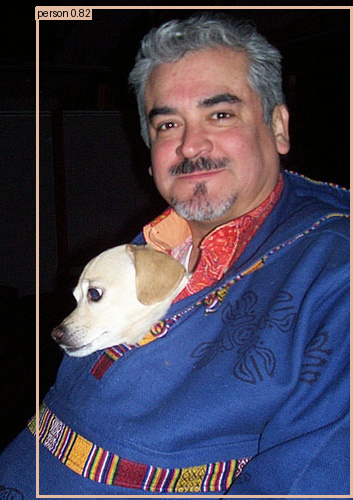

000002: 2 detections


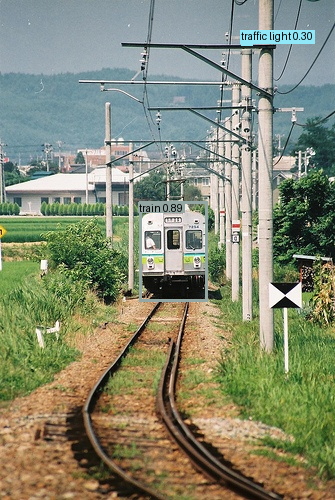

000003: 0 detections


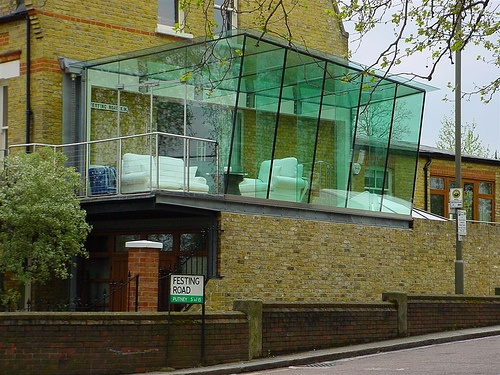

000004: 10 detections


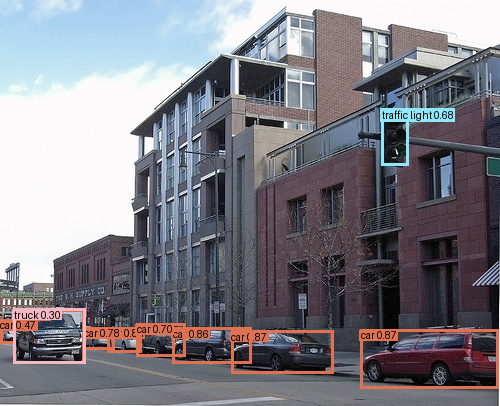

000006: 7 detections


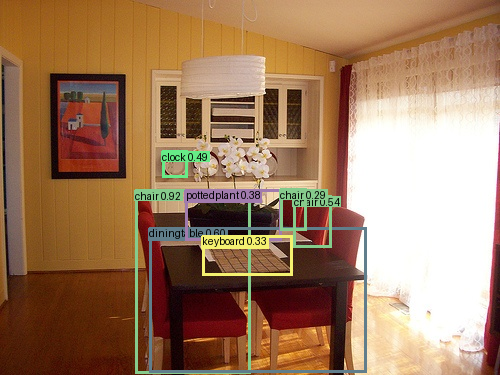

000008: 9 detections


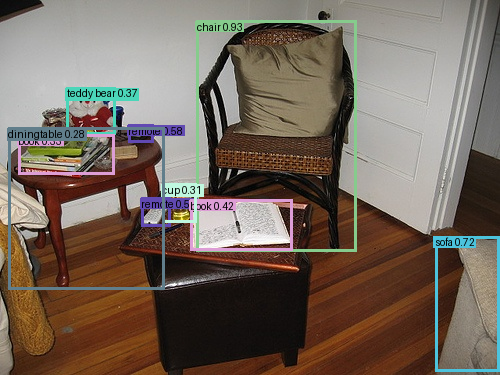

In [4]:
for s in datasets.load(DATASET, DATA_ROOT, SPLIT)[:SHOW]:
    with Image.open(s["image"]) as img:
        x, wh = preprocess(img, size, RESIZE, "pil", channels)
        boxes, scores, labels = detect(net, x[None], [wh], RESIZE)[0]
        shown = draw(img, boxes, scores, labels, names)
    shown.thumbnail((640, 640))
    print(f"{s['id']}: {len(labels)} detections")
    display(shown)

## Class mapping (out of domain, T11.2)

`MAPPINGS` of `yolo.data.datasets`, as it is; the classes of the dataset with no
equivalent are removed from the ground truth, the detections of the other classes
of the model are ignored (`eval_view`).

In [5]:
view = datasets.eval_view(DATASET, net.net["classes"])
mapping = datasets.MAPPINGS[(DATASET, family)]
rows = ["| dataset class | model class |", "|---|---|"]
rows += [f"| {c} | {mapping.get(c, '— (no equivalent, ignored)')} |"
         for c in datasets.DATASETS[DATASET].classes]
display(Markdown("\n".join(rows)))
print(f"classes evaluated ({len(view.names)}): {', '.join(view.names)}")
print(f"model classes ignored: {len(names) - len(view.names)}")

| dataset class | model class |
|---|---|
| aeroplane | aeroplane |
| bicycle | bicycle |
| bird | bird |
| boat | boat |
| bottle | bottle |
| bus | bus |
| car | car |
| cat | cat |
| chair | chair |
| cow | cow |
| diningtable | diningtable |
| dog | dog |
| horse | horse |
| motorbike | motorbike |
| person | person |
| pottedplant | pottedplant |
| sheep | sheep |
| sofa | sofa |
| train | train |
| tvmonitor | tvmonitor |

classes evaluated (20): person, bicycle, car, motorbike, aeroplane, bus, train, boat, bird, cat, dog, horse, sheep, cow, bottle, chair, sofa, pottedplant, diningtable, tvmonitor
model classes ignored: 60


## Float mAP (T14.3)

`tools/eval_voc.py`, metric of the dataset (`Dataset.metric`; COCO and FLIR: AP@[.5:.95]
and AP50). PR curves of the automatic mode of M13 (VOC metric).

all images: tier N (M12 rules)
$ python tools/eval_voc.py --net yolov8n-coco --weights weights/ultralytics/yolov8n.pt --dataset voc --resize v5 --subset 0 --preset v8 --out build/notebooks/voc/yolov8n-coco/dets --markdown build/notebooks/voc/yolov8n-coco/map_float.md --jobs 3


200/4952 images     176 s  (880 ms/image)


400/4952 images     337 s  (843 ms/image)


600/4952 images     511 s  (852 ms/image)


800/4952 images     662 s  (827 ms/image)


...

| tvmonitor | 82.0 |


| **mAP** | **79.64** |


figures : build/notebooks/voc/yolov8n-coco/dets/figures/pr.png


  (4113 s)


### yolov8n-coco (yolov8n.pt), VOC2007 test, 4952 images, 640×640 v5 (pil), conf 0.001, NMS 0.7, max 300, AP 11 points

| Class | AP |
|---|---|
| person | 86.9 |
| bicycle | 84.2 |
| car | 85.5 |
| motorbike | 86.2 |
| aeroplane | 85.9 |
| bus | 89.1 |
| train | 84.7 |
| boat | 65.5 |
| bird | 79.6 |
| cat | 83.2 |
| dog | 82.3 |
| horse | 87.2 |
| sheep | 81.2 |
| cow | 88.7 |
| bottle | 75.3 |
| chair | 65.3 |
| sofa | 74.6 |
| pottedplant | 51.3 |
| diningtable | 74.3 |
| tvmonitor | 82.0 |
| **mAP** | **79.64** |



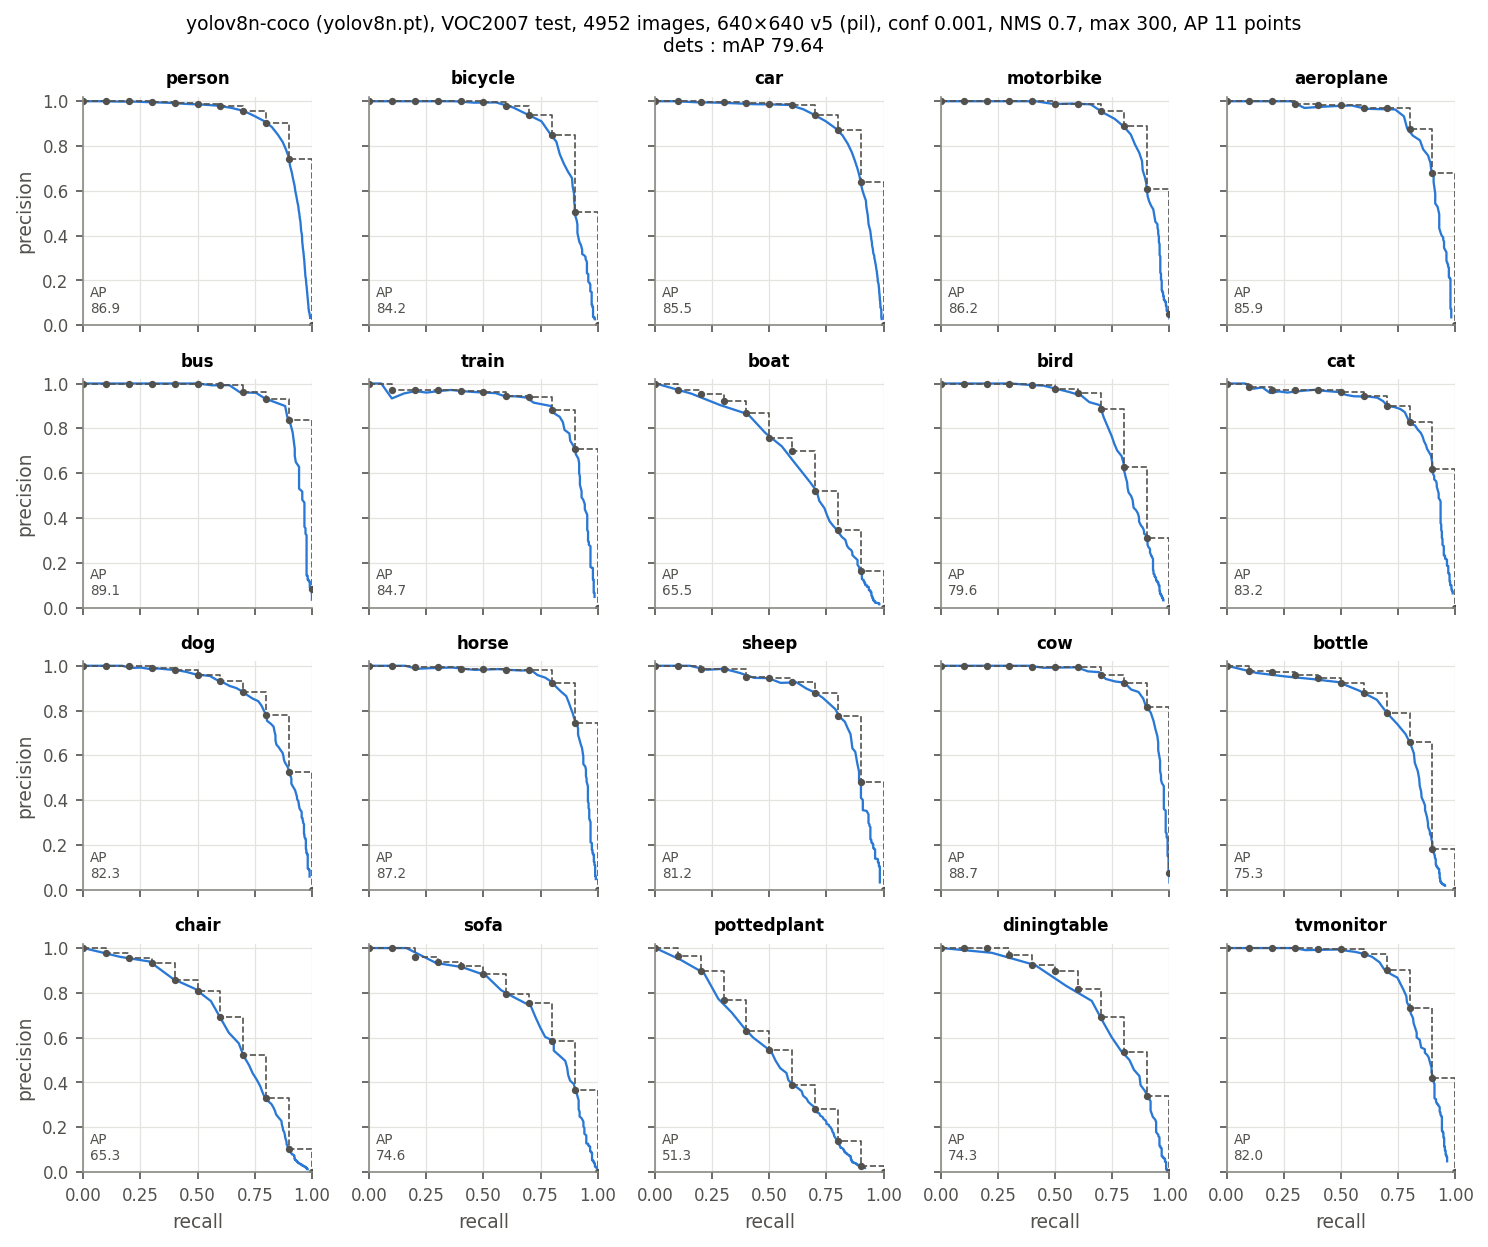

In [6]:
print(f"{SUBSET or 'all'} images: tier "
      f"{palier(SUBSET or SPLIT_IMAGES.get(DATASET))} (M12 rules)")
map_float = Path(OUT) / "map_float.md"
map_float.unlink(missing_ok=True)
C.run(C.cmd_eval_voc(NET, WEIGHTS, DATASET, RESIZE, SUBSET, METRIC, SPLIT, SIZE,
                     DATA_ROOT, out=f"{OUT}/dets", markdown=map_float, jobs=JOBS, preset=PRESET))
display(Markdown(map_float.read_text()))
for png in sorted(Path(OUT, "dets", "figures").glob("pr*.png")):
    display(Image.open(png))

## Summary

In [7]:
print(map_float.read_text())
print(f"outputs: {OUT}/; revision {TRACE['rev']}")
print("equivalent commands:")
for c in C.HISTORY:
    print("  " + c)

### yolov8n-coco (yolov8n.pt), VOC2007 test, 4952 images, 640×640 v5 (pil), conf 0.001, NMS 0.7, max 300, AP 11 points

| Class | AP |
|---|---|
| person | 86.9 |
| bicycle | 84.2 |
| car | 85.5 |
| motorbike | 86.2 |
| aeroplane | 85.9 |
| bus | 89.1 |
| train | 84.7 |
| boat | 65.5 |
| bird | 79.6 |
| cat | 83.2 |
| dog | 82.3 |
| horse | 87.2 |
| sheep | 81.2 |
| cow | 88.7 |
| bottle | 75.3 |
| chair | 65.3 |
| sofa | 74.6 |
| pottedplant | 51.3 |
| diningtable | 74.3 |
| tvmonitor | 82.0 |
| **mAP** | **79.64** |


outputs: build/notebooks/voc/yolov8n-coco/; revision 9b4e8ff
equivalent commands:
  python tools/eval_voc.py --net yolov8n-coco --weights weights/ultralytics/yolov8n.pt --dataset voc --resize v5 --subset 0 --preset v8 --out build/notebooks/voc/yolov8n-coco/dets --markdown build/notebooks/voc/yolov8n-coco/map_float.md --jobs 3
